FAQ DLA STUDENTÓW - PROJEKT AGNIESZKA DUDEK

In [ ]:
!python -m spacy download pl_core_news_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 MB 10.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pl_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
#IMPORT
import spacy
import numpy as np
import matplotlib.pyplot as plt
from math import log
import nltk
from nltk.probability import FreqDist
from nltk.draw.dispersion import dispersion_plot
from wordcloud import WordCloud
from nltk.collocations import BigramAssocMeasures
from nltk.collocations import BigramCollocationFinder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.svm import LinearSVC
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModel, Trainer, TrainingArguments
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import Trainer
from transformers import AutoModelForSequenceClassification, TrainingArguments
import pandas as pd
nltk.download('punkt')
nltk.download('punkt_tab')
import nltk
from nltk.tokenize import word_tokenize
from nltk.util import ngrams2
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer, AutoModel
nlp = spacy.load("pl_core_news_md")

In [ ]:
#ŁADOWANIE DANYCH

#FUNKCJA POMOCNICZA DO EKSTRAKCJI JEDYNIE PORZĄDANEGO TEKSTU
def clean_text(text):
    return text.replace("P: ", "").replace("O: ", "").strip()


#FUNKCJA POBIERAJĄCA DANE Z PLIKU DO ODPOWIEDNICH LIST
def load_faq_data(file_path, category):
    questions = []
    answers = []
    categories = []
    with open(file_path, 'r', encoding='utf-8') as file:
        lines = file.readlines()
        for i in range(0, len(lines), 2):
            question = clean_text(lines[i])
            answer = clean_text(lines[i + 1])
            questions.append(question)
            answers.append(answer)
            categories.append(category)
    return questions, answers, categories


# WYWOŁANIA FUNKCJI Q - QUESTIONS, A - ANSWERS, C - CATEGORIES
rekru_q, rekru_a, rekru_c = load_faq_data("rekru.txt", "rekru")
egz_q, egz_a, egz_c = load_faq_data("egzaminy.txt", "egz")
tok_q, tok_a, tok_c = load_faq_data("tok.txt", "tok")
stypendia_q, stypendia_a, stypendia_c = load_faq_data("stypendai.txt", "stypendia")
zycie_q, zycie_a, zycie_c = load_faq_data("zycie.txt", "zycie")



In [ ]:
#PRZEDSTAWIENIE STRUKTURY LIST
print(rekru_q[:5])
print(rekru_a[:5])
print(rekru_c[:5])

['Czy wynik z matury podstawowej jest wystarczający do rekrutacji na studia?', 'Jakie przedmioty z matury rozszerzonej są najczęściej brane pod uwagę przy rekrutacji?', 'Czy wynik matury z języka polskiego jest obowiązkowy do rekrutacji?', 'Czy można poprawiać wyniki matury, aby zwiększyć swoje szanse na studia?', 'Jak liczone są punkty rekrutacyjne?']
['Na niektóre kierunki tak, ale wiele uczelni wymaga również wyników z matury rozszerzonej.', 'Zależy od kierunku studiów, ale często są to matematyka, język obcy, biologia, chemia lub fizyka.', 'Tak, język polski jest obowiązkowym przedmiotem na maturze, ale jego wynik nie zawsze wpływa na rekrutację na wszystkie kierunki.', 'Tak, poprawa matury w kolejnych sesjach jest możliwa i często stosowana przez kandydatów.', 'Punkty są sumą wyników z matury (podstawowej i rozszerzonej), a czasem dodatkowo z egzaminów wstępnych lub konkursów.']
['rekru', 'rekru', 'rekru', 'rekru', 'rekru']


ANALIZA KATEGORII

In [ ]:
stopwords = nlp.Defaults.stop_words

In [ ]:
#FUNKCJA DO ANALIZY STRUKTURY POSZCZEGÓLNYCH KATEGORII
def analyze_category(name, questions, nlp):

    print(f"\n--- Kategoria: {name} ---")
    text = " ".join(questions)#WSZYSTKIE PYTANIA JAKO JEDEN TEKST
    doc = nlp(text) #PRZEKSZTAŁCENIE TEKSTU NA OBIEKT NLP

    #TOKENIZACJA
    tokens = [token.lemma_.lower() for token in doc
              if token.lemma_.lower() not in stopwords and token.is_alpha and not token.is_punct]

    total_words = len(tokens)
    unique_words = set(tokens)
    unique_count = len(unique_words)

    # MIARA HERDANA
    herdan = round(log(unique_count) / log(total_words), 3)

    print(f"Liczba słów: {total_words}")
    print(f"Liczba unikatowych słów: {unique_count}")
    print(f"Miara Herdana: {herdan}")

    #ZLICZENIA SŁÓW I NAJCZĘSTSZE SŁOWA
    fdist = FreqDist(tokens)
    print(f"najczęstsze słowa w kategorii {name}:")
    for word, freq in fdist.most_common(10):
      print(f'{word}: {freq}')

    #WYKRES
    fdist.plot(10,title=f'10 najpopularniejszych tokenów w kategorii {name}')
    plt.show()

    #ROZKŁAD NAJPOPULARNIEJSZYCH SŁÓW W TEKŚCIE - DISPERSION PLOT
    all_tokens = [token.text.lower() for token in doc if token.is_alpha and token.text.lower() not in stopwords and not token.is_punct]
    top_words = [word for word, _ in fdist.most_common(10)]

    plt.figure(figsize=(18, 3))
    dispersion_plot(all_tokens, top_words, ignore_case=True, title=f'Rozkład 10 najpopularniejszych słów w kategorii {name}')

    #WORDCLOUD
    cloud = WordCloud(max_font_size=80,colormap="hsv").generate_from_frequencies(fdist)
    plt.figure(figsize=(16,12))
    plt.imshow(cloud, interpolation='bilinear')
    plt.axis('off')
    plt.show()


    #NAJCZĘŚCIEJ WYSTĘPUJĄCE BIGRAMY
    bigram_measures = BigramAssocMeasures()
    finder = BigramCollocationFinder.from_words(tokens, 3) #okno maks 3 słów
    finder.apply_freq_filter(10)
    print(f"najczęstsze występujące bigramy w kategorii {name}:")
    print(finder.nbest(bigram_measures.likelihood_ratio, 5) )



--- Kategoria: Rekrutacja ---
Liczba słów: 711
Liczba unikatowych słów: 283
Miara Herdana: 0.86
najczęstsze słowa w kategorii Rekrutacja:
rekrutacja: 57
studia: 40
móc: 30
dokument: 21
wynik: 16
system: 16
rekrutacyjny: 15
musieć: 14
matura: 13
kierunek: 13


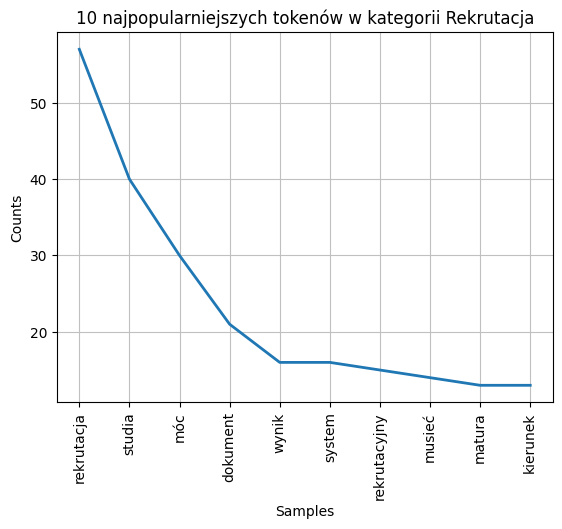

<Figure size 1800x300 with 0 Axes>

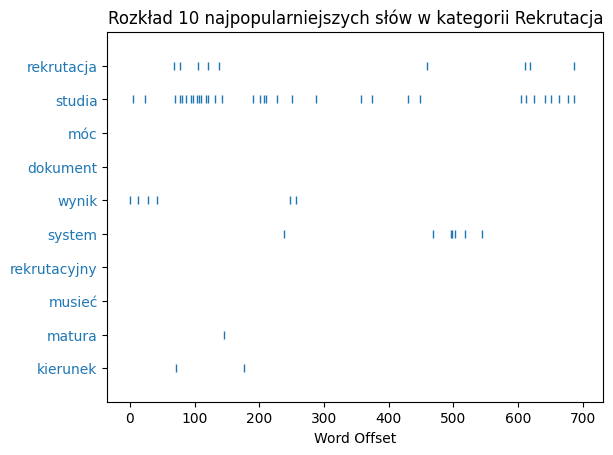

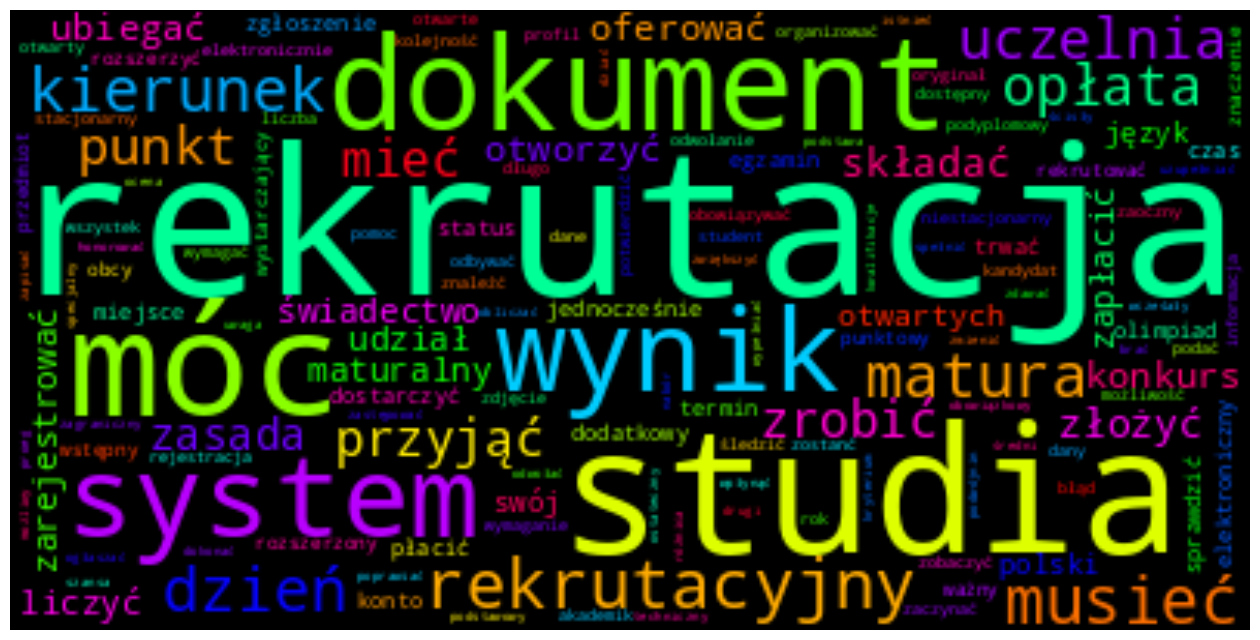

najczęstsze występujące bigramy w kategorii Rekrutacja:
[('opłata', 'rekrutacyjny'), ('rekrutacja', 'studia')]

--- Kategoria: Egzaminy ---
Liczba słów: 797
Liczba unikatowych słów: 320
Miara Herdana: 0.863
najczęstsze słowa w kategorii Egzaminy:
egzamin: 99
móc: 57
student: 21
praca: 18
termin: 16
ocena: 16
obrona: 14
mieć: 13
egzaminacyjny: 11
zdawać: 11


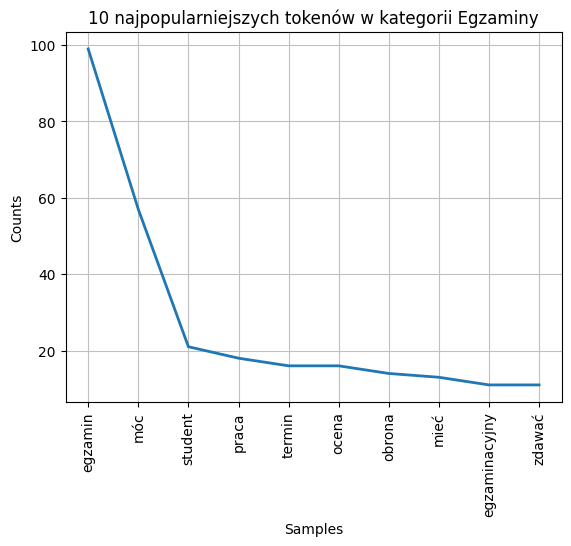

<Figure size 1800x300 with 0 Axes>

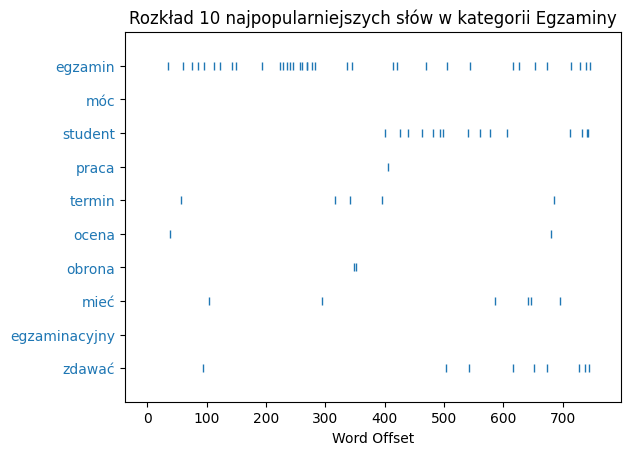

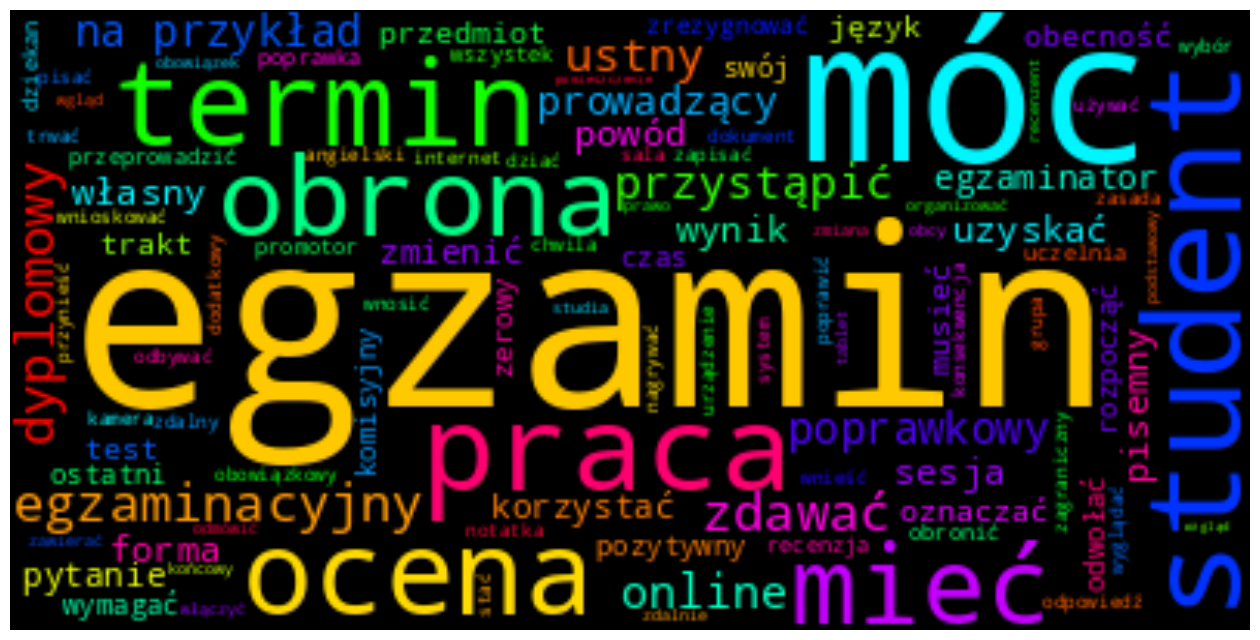

najczęstsze występujące bigramy w kategorii Egzaminy:
[('zdawać', 'egzamin'), ('egzamin', 'egzamin'), ('egzamin', 'móc'), ('móc', 'egzamin')]

--- Kategoria: Tok studiów ---
Liczba słów: 710
Liczba unikatowych słów: 253
Miara Herdana: 0.843
najczęstsze słowa w kategorii Tok studiów:
przedmiot: 42
student: 24
urlop: 24
móc: 21
studia: 20
dziekański: 20
zajęcia: 18
uczelnia: 18
ects: 18
punkt: 17


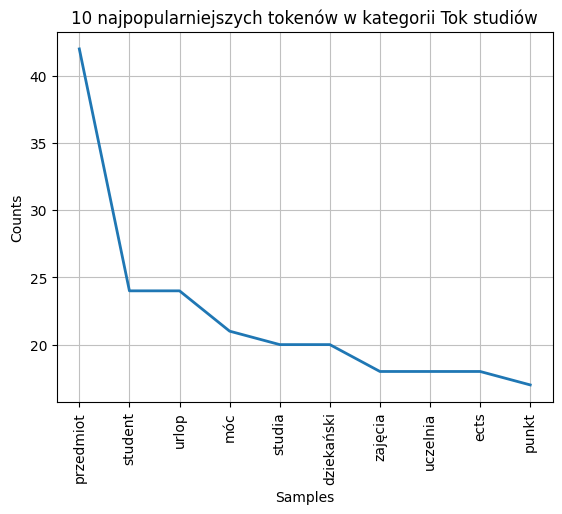

<Figure size 1800x300 with 0 Axes>

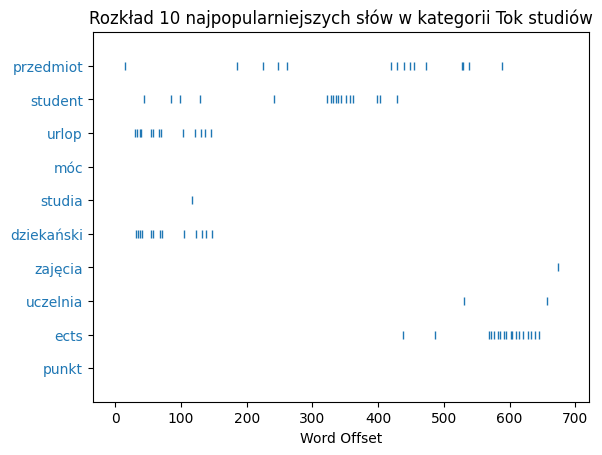

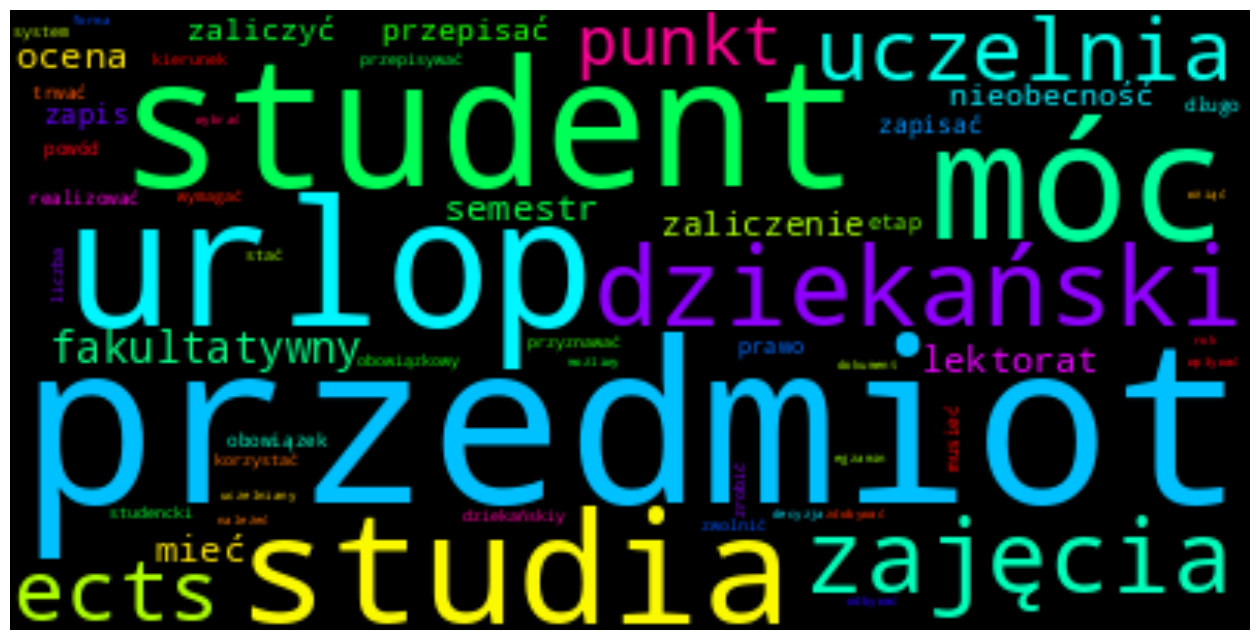

najczęstsze występujące bigramy w kategorii Tok studiów:
[('urlop', 'dziekański'), ('punkt', 'ects'), ('przedmiot', 'fakultatywny')]

--- Kategoria: Stypendia ---
Liczba słów: 683
Liczba unikatowych słów: 268
Miara Herdana: 0.857
najczęstsze słowa w kategorii Stypendia:
stypendium: 74
móc: 29
erasmus: 24
praktyka: 22
naukowy: 20
student: 14
sportowy: 13
otrzymać: 13
uczelnia: 12
ubiegać: 12


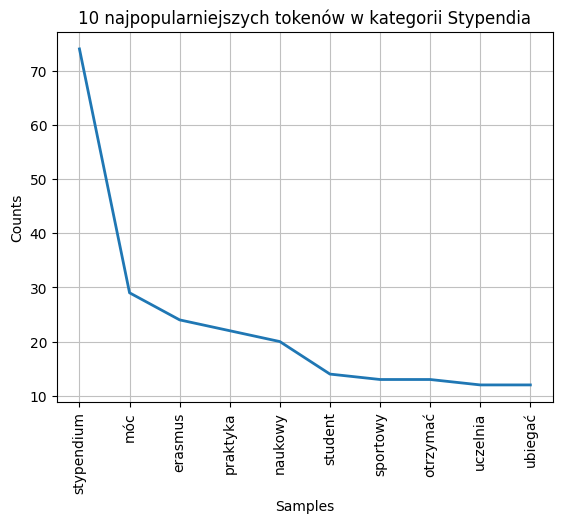

<Figure size 1800x300 with 0 Axes>

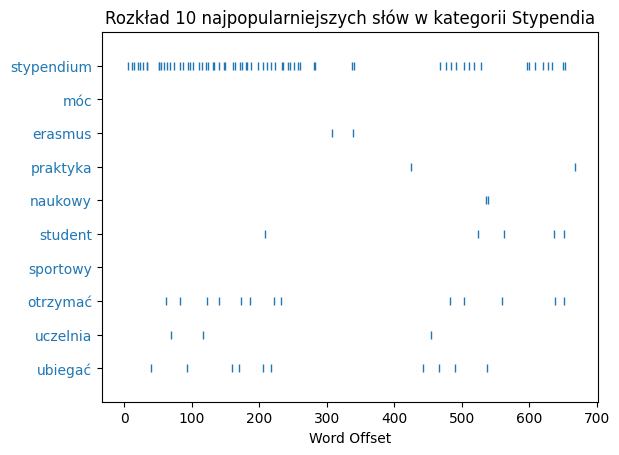

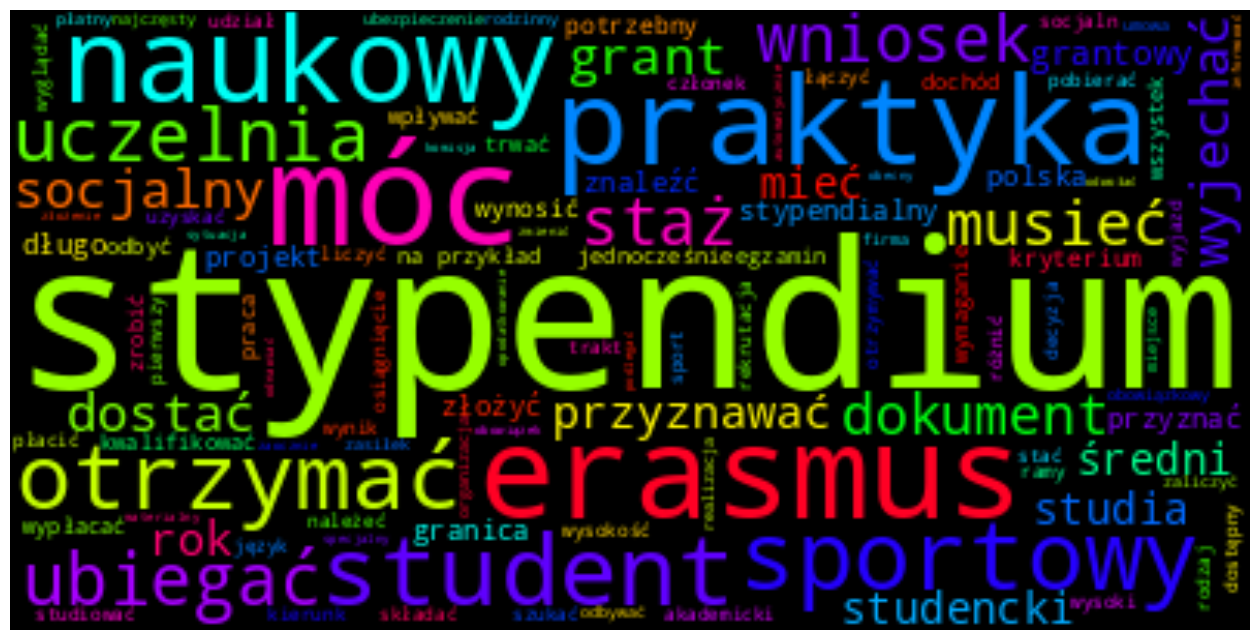

najczęstsze występujące bigramy w kategorii Stypendia:
[('stypendium', 'sportowy'), ('stypendium', 'naukowy'), ('otrzymać', 'stypendium'), ('móc', 'stypendium'), ('stypendium', 'stypendium')]

--- Kategoria: Życie studenckie ---
Liczba słów: 649
Liczba unikatowych słów: 242
Miara Herdana: 0.848
najczęstsze słowa w kategorii Życie studenckie:
móc: 34
sportowy: 26
studencki: 25
sekcja: 23
uczelnia: 20
organizacja: 20
naukowy: 20
student: 18
mieć: 17
koło: 16


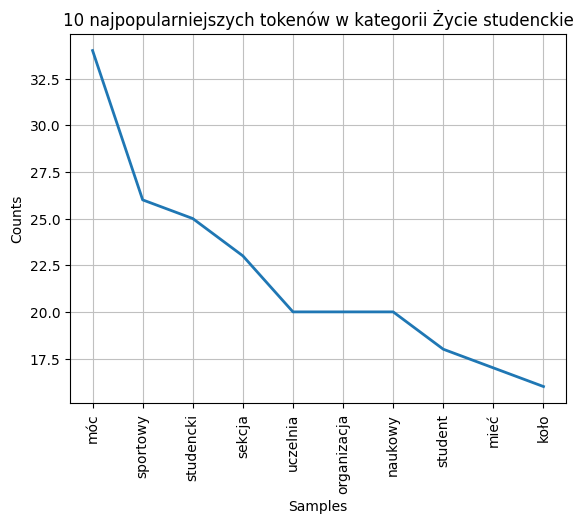

<Figure size 1800x300 with 0 Axes>

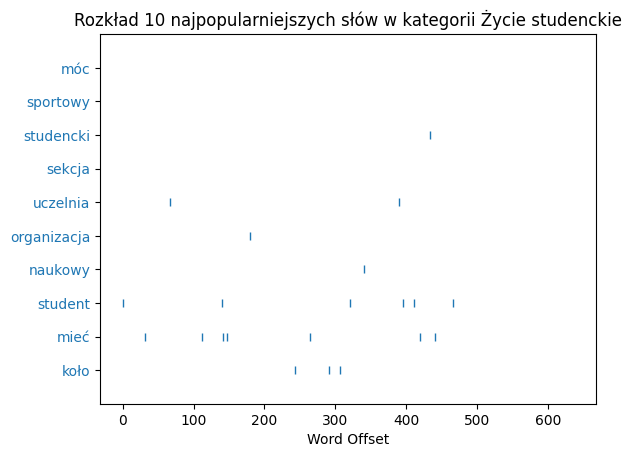

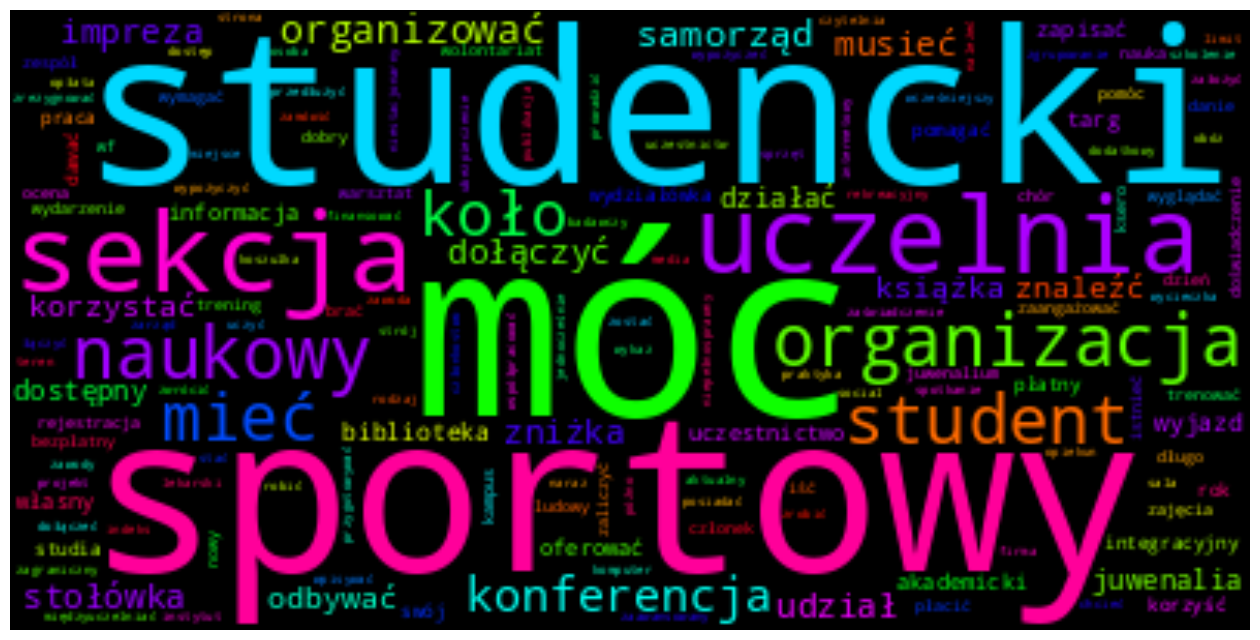

najczęstsze występujące bigramy w kategorii Życie studenckie:
[('sekcja', 'sportowy'), ('koło', 'naukowy'), ('organizacja', 'studencki')]


In [ ]:
analyze_category("Rekrutacja", rekru_q, nlp)
analyze_category("Egzaminy", egz_q, nlp)
analyze_category("Tok studiów", tok_q, nlp)
analyze_category("Stypendia", stypendia_q, nlp)
analyze_category("Życie studenckie", zycie_q, nlp)


In [ ]:
# POŁĄCZENIE TEKSTÓW
all_q = rekru_q + egz_q + tok_q + stypendia_q + zycie_q
all_c = rekru_c + egz_c + tok_c + stypendia_c + zycie_c

# PODZIAŁ NA ZBIÓR TRENINGOWY I TESTOWY 80/20
X_train, X_test, y_train, y_test = train_test_split(
    all_q, all_c, test_size=0.2, random_state=42, stratify=all_c
)

# TWORZENIE TF-IDF
vectorizer = TfidfVectorizer(
    tokenizer=lambda text: [token.lemma_.lower() for token in nlp(text) if token.is_alpha and not token.is_stop],
    max_features=2000
)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


KLASYFIKACJA NB

Raport klasyfikacji:

              precision    recall  f1-score   support

         egz       0.93      0.97      0.95        29
       rekru       0.85      0.93      0.89        30
   stypendia       0.96      0.81      0.88        31
         tok       0.83      0.86      0.85        29
       zycie       0.87      0.87      0.87        30

    accuracy                           0.89       149
   macro avg       0.89      0.89      0.89       149
weighted avg       0.89      0.89      0.89       149



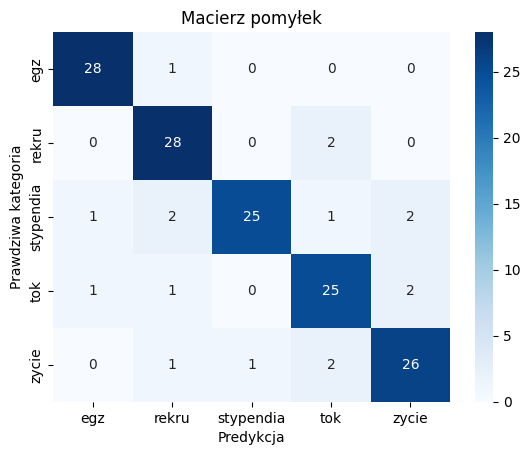


Najbardziej różnicujące słowa na kategorie:

egz: egzamin, praca, móc, ocena, obrona, dyplomowy, termin, zdawać, egzaminacyjny, przystąpić
rekru: rekrutacja, studia, dokument, rekrutacyjny, móc, system, wynik, dzień, matura, przyjąć
stypendia: stypendium, praktyka, naukowy, erasmus, ubiegać, staż, otrzymać, sportowy, wniosek, uczelnia
tok: przedmiot, urlop, student, zajęcia, ects, dziekański, punkt, uczelnia, lektorat, semestr
zycie: studencki, sportowy, organizacja, sekcja, móc, konferencja, koło, samorząd, naukowy, organizować


In [ ]:
# KLASYFIKATOR NAIVE BAYES
clf = MultinomialNB()
clf.fit(X_train_tfidf, y_train)

# PREDYKCJA
y_pred = clf.predict(X_test_tfidf)

# EWALUACJA
print("Raport klasyfikacji:\n")
print(classification_report(y_test, y_pred))

# MACIERZ POMYŁEK
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_, cmap="Blues")
plt.xlabel("Predykcja")
plt.ylabel("Prawdziwa kategoria")
plt.title("Macierz pomyłek")
plt.show()

# NAJBARDZIEJ RÓŻNICUJĄCE CECHY (SŁOWA) DLA KATEGORII

feature_names = vectorizer.get_feature_names_out()
n_top_words = 10

print("\nNajbardziej różnicujące słowa na kategorie:\n")
for i, category in enumerate(clf.classes_):
    top_indices = np.argsort(clf.feature_log_prob_[i])[::-1][:n_top_words] #clf.feature_log_prob_ TABLICE LOGARYTMÓW PRAWDOPODBIEŃSTWA CECH SŁÓW W KAŻDEJ KLASIE
    top_features = [feature_names[j] for j in top_indices]
    print(f"{category}: {', '.join(top_features)}")


MODEL KLASYFIKACJI REGRESJA LOGISTYCZNA

Dokładność Logistic Regression: 0.899

Raport klasyfikacji Logistic Regression:

              precision    recall  f1-score   support

         egz       0.97      1.00      0.98        29
       rekru       0.88      0.97      0.92        30
   stypendia       0.96      0.81      0.88        31
         tok       0.79      0.79      0.79        29
       zycie       0.90      0.93      0.92        30

    accuracy                           0.90       149
   macro avg       0.90      0.90      0.90       149
weighted avg       0.90      0.90      0.90       149



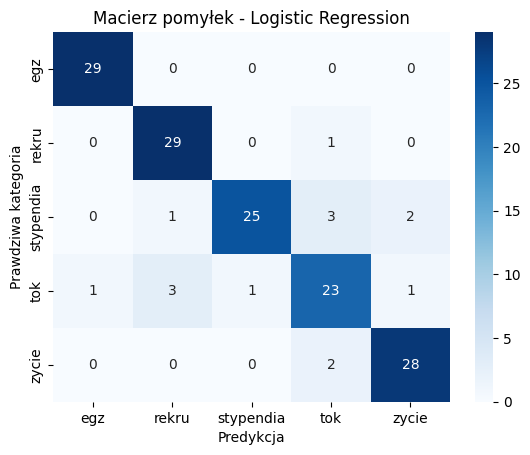


Najbardziej różnicujące słowa na kategorie - Logistic Regression:

egz: egzamin, praca, obrona, egzaminacyjny, dyplomowy, ocena, pytanie, sesja, przystąpić, ustny
rekru: rekrutacja, rekrutacyjny, studia, dzień, dokument, matura, przyjąć, system, kierunek, opłata
stypendia: stypendium, praktyka, erasmus, staż, grant, erasmusa, grantowy, wniosek, otrzymać, wyjechać
tok: przedmiot, urlop, ects, dziekański, zajęcia, lektorat, nieobecność, semestr, zaliczenie, fakultatywny
zycie: konferencja, sekcja, samorząd, organizacja, studencki, sportowy, koło, impreza, organizować, stołówka


In [ ]:
# KLASYFIKATOR LOGISTIC REGRESSION
clf_lr = LogisticRegression(max_iter=1000, random_state=42)
clf_lr.fit(X_train_tfidf, y_train)

# PREDYKCJA
y_pred_lr = clf_lr.predict(X_test_tfidf)

# EWALUACJA
acc_lr = accuracy_score(y_test, y_pred_lr)
print(f"Dokładność Logistic Regression: {acc_lr:.3f}\n")
print("Raport klasyfikacji Logistic Regression:\n")
print(classification_report(y_test, y_pred_lr))

# MACIERZ POMYŁEK
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=clf_lr.classes_)
sns.heatmap(cm_lr, annot=True, fmt='d', xticklabels=clf_lr.classes_, yticklabels=clf_lr.classes_, cmap="Blues")
plt.xlabel("Predykcja")
plt.ylabel("Prawdziwa kategoria")
plt.title("Macierz pomyłek - Logistic Regression")
plt.show()

#NAJBARDZIEJ RÓŻNICUJĄCE CECHY DLA LR

feature_names = vectorizer.get_feature_names_out()
n_top_words = 10

print("\nNajbardziej różnicujące słowa na kategorie - Logistic Regression:\n")
for i, category in enumerate(clf_lr.classes_):
    # WSPÓŁCZYNNIKI WAG
    top_indices = np.argsort(clf_lr.coef_[i])[::-1][:n_top_words]
    top_features = [feature_names[j] for j in top_indices]
    print(f"{category}: {', '.join(top_features)}")


MODEL SVM KLASYFIKACJA

Dokładność LinearSVC: 0.906

Raport klasyfikacji LinearSVC:

              precision    recall  f1-score   support

         egz       0.97      0.97      0.97        29
       rekru       0.94      0.97      0.95        30
   stypendia       0.96      0.84      0.90        31
         tok       0.77      0.83      0.80        29
       zycie       0.90      0.93      0.92        30

    accuracy                           0.91       149
   macro avg       0.91      0.91      0.91       149
weighted avg       0.91      0.91      0.91       149



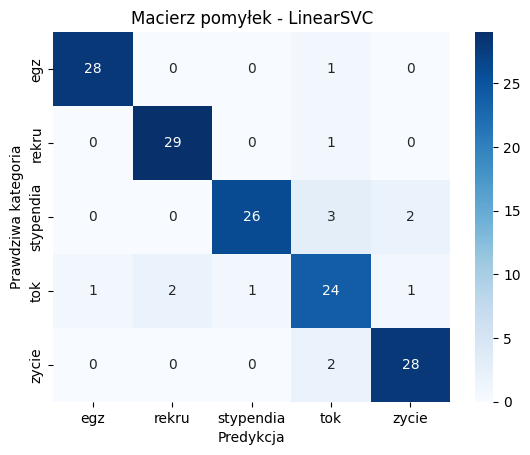


Najbardziej różnicujące słowa na kategorie - LinearSVC:

egz: egzamin, obrona, egzaminacyjny, praca, dyplomowy, sesja, pytanie, ocena, przystąpić, obronić
rekru: rekrutacja, rekrutacyjny, dzień, matura, przyjąć, dokument, wstępny, studia, maturalny, opłata
stypendia: stypendium, praktyka, erasmus, erasmusa, staż, grant, grantowy, stypendialny, granica, partnerski
tok: przedmiot, lektorat, urlop, ects, nieobecność, semestr, dziekański, zaliczenie, prawo, zajęcia
zycie: konferencja, samorząd, sekcja, impreza, organizacja, koło, stołówka, juwenalia, zniżka, wydziałówka


In [ ]:
#KLASYFIKATOR SVM (LinearSVC)
clf_svm = LinearSVC(max_iter=10000, random_state=42)
clf_svm.fit(X_train_tfidf, y_train)

# PREDYKCJA
y_pred_svm = clf_svm.predict(X_test_tfidf)

# EWALUACJA
acc_svm = accuracy_score(y_test, y_pred_svm)
print(f"Dokładność LinearSVC: {acc_svm:.3f}\n")
print("Raport klasyfikacji LinearSVC:\n")
print(classification_report(y_test, y_pred_svm))

# MACIERZ POMYŁEK
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=clf_svm.classes_)
sns.heatmap(cm_svm, annot=True, fmt='d', xticklabels=clf_svm.classes_, yticklabels=clf_svm.classes_, cmap="Blues")
plt.xlabel("Predykcja")
plt.ylabel("Prawdziwa kategoria")
plt.title("Macierz pomyłek - LinearSVC")
plt.show()

# NAJBARDZIEJ RÓŻNICUJĄCE CECHY DLA LinearSVC

feature_names = vectorizer.get_feature_names_out()
n_top_words = 10

print("\nNajbardziej różnicujące słowa na kategorie - LinearSVC:\n")
for i, category in enumerate(clf_svm.classes_):
    # WSPÓŁCZYNNIKI WAG
    top_indices = np.argsort(clf_svm.coef_[i])[::-1][:n_top_words]
    top_features = [feature_names[j] for j in top_indices]
    print(f"{category}: {', '.join(top_features)}")

In [ ]:
!pip install sacremoses

In [ ]:
!pip install transformers

In [ ]:
!pip install torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 975.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 86.5 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitli

MODEL herBERT KLASYFIKACJA

In [ ]:
#HERBERT WERSJA 1
# KODOWANIE ETYKIET -> NAZWY KATEGORII NA LICZBY
label_encoder = LabelEncoder()
all_labels_encoded = label_encoder.fit_transform(all_c)

# PODZIAŁ ZBIORU
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    all_q, all_labels_encoded, test_size=0.3, random_state=42, stratify=all_labels_encoded #STRATIFY - RÓWNA PROPORCJA KATEGORII
)
val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size=0.33, random_state=42, stratify=temp_labels
)

#ŁADOWANIE TOKENIZATORA DLA MODELU HERBERT
tokenizer = AutoTokenizer.from_pretrained("allegro/herbert-base-cased")

# TOKENIZACJA
def tokenize_function(texts):
    return tokenizer(texts, padding=True, truncation=True, max_length=128)

train_encodings = tokenize_function(train_texts)
val_encodings = tokenize_function(val_texts)
test_encodings = tokenize_function(test_texts)

# DATASET PyTorch
class FAQDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item
    def __len__(self):
        return len(self.labels)

train_dataset = FAQDataset(train_encodings, train_labels)
val_dataset = FAQDataset(val_encodings, val_labels)
test_dataset = FAQDataset(test_encodings, test_labels)


# DEFINICJA MODELU
class CustomSequenceClassifier(nn.Module):
    def __init__(self, model_name, num_labels, dropout_prob=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name) #ŁADUJE MODEL HERBERT
        hidden_size = self.bert.config.hidden_size #ROZMIAR WEKTORA WYJŚCIOWEGO

        self.dropout = nn.Dropout(dropout_prob) #DROPOUT
        self.layer_norm = nn.LayerNorm(hidden_size) #WARSTWA NORMALIZACJI
        self.classifier = nn.Linear(hidden_size, num_labels) # WARSTWA KLASYFIKUJĄCA

    def forward(self, input_ids, attention_mask=None, token_type_ids=None, labels=None):
        outputs = self.bert(input_ids=input_ids,
                            attention_mask=attention_mask,
                            token_type_ids=token_type_ids)
        pooled_output = outputs.pooler_output  # [batch_size, hidden_size]

        x = self.dropout(pooled_output)
        x = self.layer_norm(x)
        logits = self.classifier(x)

        loss = None
        if labels is not None: #LICZY STRATE
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, self.classifier.out_features), labels.view(-1))

        return {'loss': loss, 'logits': logits} if loss is not None else {'logits': logits} #ZWRACA PREDYKCJE I STRATE

#TWORZENIE INSTANCJI MODELU
model_name = "allegro/herbert-base-cased"
num_labels = len(label_encoder.classes_)
model = CustomSequenceClassifier(model_name, num_labels)

# PARAMETRY TRENINGU
training_args = TrainingArguments(
    output_dir="./results_faq",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    logging_dir="./logs_faq",
    logging_steps=20,
    metric_for_best_model="accuracy",
    save_total_limit=2,
    report_to="none",
)

#DOKŁADNOŚĆ
def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return {"accuracy": accuracy_score(p.label_ids, preds)}

#TRAINER Z DOSTOSOWANĄ STRATĄ
#DOSTOSOWUJE SPOSÓB LICZENIA STRATY DLA NASZEGO MODELU
class WrappedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        loss = outputs['loss'] if 'loss' in outputs else None
        return (loss, outputs) if return_outputs else loss

#UTWORZENIE OBIEKTU TRAINER
trainer = WrappedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

# TRENING
trainer.train()

# EWALUACJA
print("Dokładność na zbiorze testowym:")
print(trainer.evaluate(test_dataset))


# FUNKCJA PREDYKCJI
def predict(text):
    model.eval()
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=128)#TOKENIZACJA PYTANIA
    with torch.no_grad(): #MODEL BEZ LICZENIA GRADIENTÓW
        outputs = model(**inputs)
        logits = outputs['logits']
        predicted_class = torch.argmax(logits, dim=1).item() #KATEGORIA O NAJWYŻSZYM WYNIKU
    return label_encoder.inverse_transform([predicted_class])[0] #DEKODUJE LICZBĘ NA NAZWE KATEGORII

#PRZYKŁAD
print("\nPrzykładowe predykcje:")
examples = [
    "Jakie są terminy rekrutacji?",
    "Kiedy odbędą się egzaminy?",
    "Jak ubiegać się o stypendium?",
    "Jakie są zasady życia studenckiego?"
]

for ex in examples:
    print(f"> {ex}\n>> {predict(ex)}\n")


tokenizer_config.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/907k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/556k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/129 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/654M [00:00<?, ?B/s]

Some weights of the model checkpoint at allegro/herbert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.sso.sso_relationship.bias', 'cls.sso.sso_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


model.safetensors:   0%|          | 0.00/654M [00:00<?, ?B/s]

Step,Training Loss
20,1.678000
40,1.605300
60,1.274000
80,0.607100
100,0.378200
120,0.318800
140,0.245100
160,0.109300
180,0.064400


Dokładność na zbiorze testowym:


{'eval_loss': 0.14236021041870117, 'eval_accuracy': 0.9459459459459459, 'eval_runtime': 6.0423, 'eval_samples_per_second': 12.247, 'eval_steps_per_second': 1.655, 'epoch': 3.0}

Przykładowe predykcje:
> Jakie są terminy rekrutacji?
>> rekru

> Kiedy odbędą się egzaminy?
>> egz

> Jak ubiegać się o stypendium?
>> stypendia

> Jakie są zasady życia studenckiego?
>> zycie



In [ ]:
#KLASYFIKACJA HERBERT WERSJA 2

# KODOWANIE ETYKIET
label_encoder = LabelEncoder()
all_labels_encoded = label_encoder.fit_transform(all_c)

# PODZIAŁ
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    all_q, all_labels_encoded, test_size=0.3, random_state=42, stratify=all_labels_encoded
)
val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size=0.33, random_state=42, stratify=temp_labels
)

tokenizer = AutoTokenizer.from_pretrained("allegro/herbert-base-cased")

# TOKENIZACJA
train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=128)
val_encodings = tokenizer(val_texts, truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(test_texts, truncation=True, padding=True, max_length=128)


class TextDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item
    def __len__(self):
        return len(self.labels)

train_dataset = TextDataset(train_encodings, train_labels)
val_dataset = TextDataset(val_encodings, val_labels)
test_dataset = TextDataset(test_encodings, test_labels)


#DEFINICJA MODELU
num_labels = len(label_encoder.classes_)
model = AutoModelForSequenceClassification.from_pretrained("allegro/herbert-base-cased", num_labels=num_labels)

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    logging_dir="./logs",
    logging_steps=10,
    report_to="none",
)


def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds)}


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

trainer.train()

print("Dokładność na zbiorze testowym:")
print(trainer.evaluate(test_dataset))


def predict(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=128)
    with torch.no_grad():
        outputs = model(**inputs)
        predicted_class = torch.argmax(outputs.logits, dim=1).item()
    return label_encoder.inverse_transform([predicted_class])[0]


print("\nPrzykładowe predykcje:")
examples = [
    "Jakie są terminy rekrutacji?",
    "Kiedy odbędą się egzaminy?",
    "Jak ubiegać się o stypendium?",
    "Jakie są zasady życia studenckiego?"
]

for ex in examples:
    print(f"> {ex}\n>> {predict(ex)}\n")

#MODEL 2 MA WYŻSZE ACCURACY (95 VS 97), JEDNAK NA REALNYCH PRZYKŁADACH WYPADA GORZEJ (PRZYKLAD PRZY ODPOWIEDZIACH NA PYTANIA NGRAMS), TAK WIEC DO DALSZEJ ANALIZY UŻYWAM WERSJI JEDEN

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at allegro/herbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
10,1.672000
20,1.561500
30,1.549100
40,1.418400
50,1.036300
60,0.767800
70,0.612100
80,0.362200
90,0.310000
100,0.253200


Dokładność na zbiorze testowym:


{'eval_loss': 0.08195694535970688, 'eval_accuracy': 0.972972972972973, 'eval_runtime': 4.9573, 'eval_samples_per_second': 14.927, 'eval_steps_per_second': 2.017, 'epoch': 3.0}

Przykładowe predykcje:
> Jakie są terminy rekrutacji?
>> rekru

> Kiedy odbędą się egzaminy?
>> egz

> Jak ubiegać się o stypendium?
>> stypendia

> Jakie są zasady życia studenckiego?
>> zycie



In [ ]:
examples = [
    "W jakich godzianch otwarty jest sekretariat?",
    "Jak długi jest tok studiów?",
    "Czy są kółka naukowe?",
    "Czy mogę biegać w ramach zajęć dodatkowych?",
]

for ex in examples:
    print(f"> {ex}\n>> {predict(ex)}\n")

> W jakich godzianch otwarty jest sekretariat?
>> rekru

> Jak długi jest tok studiów?
>> tok

> Czy są kółka naukowe?
>> zycie

> Czy mogę biegać w ramach zajęć dodatkowych?
>> zycie



In [ ]:
#PORÓWNANIE MODELI
test_examples = {
    "rekrutacja": [
        "Gdzie mogę znaleźć harmonogram rekrutacji?",
        "Jakie dokumenty trzeba złożyć przy zapisie na studia?"
    ],
    "tok studiów": [
        "Czy mogę przedłużyć semestr?",
        "Jakie są obowiązkowe przedmioty na pierwszym roku?"
    ],
    "stypendia i erasmus": [
        "Jakie warunki trzeba spełnić, by dostać stypendium socjalne?",
        "Czy mogę pojechać na Erasmusa w drugim semestrze?"
    ],
    "życie studenckie": [
        "Gdzie znajdę informacje o kołach naukowych?",
        "Czy uczelnia organizuje jakieś wydarzenia integracyjne?"
    ],
    "egzaminy i sesja": [
        "Kiedy rozpoczyna się sesja egzaminacyjna?",
        "Czy poprawka z egzaminu jest płatna?"
    ]
}

def predict_nb(text):
    vec = vectorizer.transform([text])
    return clf.predict(vec)[0]

def predict_lr(text):
    vec = vectorizer.transform([text])
    return clf_lr.predict(vec)[0]

def predict_svm(text):
    vec = vectorizer.transform([text])
    return clf_svm.predict(vec)[0]





In [ ]:
rows = []

for true_label, examples in test_examples.items():
    for example in examples:
        row = {
            "tekst": example,
            "kategoria_prawdziwa": true_label,
            "NaiveBayes": predict_nb(example),
            "LogReg": predict_lr(example),
            "SVM": predict_svm(example),
            "HerBERT": predict(example)
        }
        rows.append(row)

df = pd.DataFrame(rows)
print(df)

#DLA KAŻDEGO W SUMIE WYSZŁO TO SAMO, JEDNAK NAJLEPSZE ACCURACY DLA MODELU BERT, TAKŻE TO JEGO UŻYJE DO PREDYKCJI KATEGORII W FUNKCJACH DO ODPOWIEDZI NA PYTANIA

                                               tekst  kategoria_prawdziwa  \
0         Gdzie mogę znaleźć harmonogram rekrutacji?           rekrutacja   
1  Jakie dokumenty trzeba złożyć przy zapisie na ...           rekrutacja   
2                       Czy mogę przedłużyć semestr?          tok studiów   
3  Jakie są obowiązkowe przedmioty na pierwszym r...          tok studiów   
4  Jakie warunki trzeba spełnić, by dostać stypen...  stypendia i erasmus   
5  Czy mogę pojechać na Erasmusa w drugim semestrze?  stypendia i erasmus   
6        Gdzie znajdę informacje o kołach naukowych?     życie studenckie   
7  Czy uczelnia organizuje jakieś wydarzenia inte...     życie studenckie   
8          Kiedy rozpoczyna się sesja egzaminacyjna?     egzaminy i sesja   
9               Czy poprawka z egzaminu jest płatna?     egzaminy i sesja   

  NaiveBayes     LogReg        SVM    HerBERT  
0      rekru      rekru      rekru      rekru  
1      rekru      rekru      rekru      rekru  
2       

Szukanie odpowiedzi

In [ ]:
#DANE DO WYSZUKIWANIA ODPOWIEDZI W POSZCZEGÓLNYCH KATEGORIACH
faq_data = {
    "rekru": (rekru_q, rekru_a),
    "egz": (egz_q, egz_a),
    "tok": (tok_q, tok_a),
    "stypendia": (stypendia_q, stypendia_a),
    "zycie": (zycie_q, zycie_a),
}

#DANE DO TESTOWANIA - CZĘŚĆ PYTAŃ IDENTYCZNYCH JAK W BAZIE, CZĘŚĆ LEKKO PRZEROBIONYCH
test_data = {
  'Jakie są główne etapy rekrutacji na studia?': 'Jakie są główne etapy rekrutacji na studia?',
  'Jakie są etapy rekrutacji?': 'Jakie są główne etapy rekrutacji na studia?',
  'Co zrobić, jeśli zapomnę hasła do systemu rekrutacji?': 'Co zrobić, jeśli zapomnę hasła do systemu rekrutacji?',
  'Co jak zapomnę hasła?': 'Co zrobić, jeśli zapomnę hasła do systemu rekrutacji?',
  'Co jak nie będę pamiętać hasła do systemu?': 'Co zrobić, jeśli zapomnę hasła do systemu rekrutacji?',
  'Jakie są kryteria przyznawania stypendium naukowego?': 'Jakie są kryteria przyznawania stypendium naukowego?',
  'Co trzeba zrobić by otrzymać stypendium naukowe?': 'Jakie są kryteria przyznawania stypendium naukowego?',
  'Kto może otrzymać stypendium sportowe?': 'Kto może otrzymać stypendium sportowe?',
  'Komu przysługuje stypendium sportowe?': 'Kto może otrzymać stypendium sportowe?',
  'Na jak długo można wyjechać na Erasmusa?': 'Na jak długo można wyjechać na Erasmusa?',
  'Na ile mogę jechać na Erasmusa?': 'Na jak długo można wyjechać na Erasmusa?',
  'Ile nieobecności można mieć bez konsekwencji?': 'Ile nieobecności można mieć bez konsekwencji?',
  'Ile mogę mieć nieobecność?': 'Ile nieobecności można mieć bez konsekwencji?',
  'Czy student może być zwolniony z lektoratu?': 'Czy student może być zwolniony z lektoratu?',
  'Czy mogę zostać zwolniona z lektoratu?': 'Czy student może być zwolniony z lektoratu?',
  'Jak długo trwa semestr letni?': 'Jak długo trwa semestr letni?',
  'Ile trwa letni semestr?': 'Jak długo trwa semestr letni?',
  'Czym są juwenalia?': 'Czym są juwenalia?',
  'Co to Juwenalia?': 'Czym są juwenalia?',
  'Jak mogę zapisać się do sekcji sportowej na uczelni?': 'Jak mogę zapisać się do sekcji sportowej na uczelni?',
  'Co zrobić, żeby zapisać się do sekcji sportowej?': 'Jak mogę zapisać się do sekcji sportowej na uczelni?',
  'Czy mogę korzystać z biblioteki jako student?': 'Czy mogę korzystać z biblioteki jako student?',
  'Czy będąc studentem mogę za darmo korzystać z biblioteki?': 'Czy mogę korzystać z biblioteki jako student?',
  'Czy egzamin może odbywać się w trybie zdalnym?': 'Czy egzamin może odbywać się w trybie zdalnym?',
  'Czy egzaminy mogą odbywać się zdalnie?': 'Czy egzamin może odbywać się w trybie zdalnym?',
  'Czy w trakcie egzaminu można wyjść do toalety?': 'Czy w trakcie egzaminu można wyjść do toalety?',
  'Czy podczas egzaminu mogę wyjść do łazienki?': 'Czy w trakcie egzaminu można wyjść do toalety?',
  'Jakie oceny składają się na ocenę końcową ze studiów?': 'Jakie oceny składają się na ocenę końcową ze studiów?',
  'Co składa się na ocenę na koniec studiów?': 'Jakie oceny składają się na ocenę końcową ze studiów?'
}

In [ ]:
#UNIWERSALNA FUNKCJA DO EWALUACJA MODELI

def model_compar(curr_model):
  #accuracy top1

  ilosc_pytan = len(test_data)
  ilosc_dobrych = 0
  ilosc_dobrych_3 = 0

  for sent, val in test_data.items():
    results = curr_model(sent, predict(sent))
    for ans, que, score in results:
      if que == val:
        ilosc_dobrych += 1

  print(f'accuracy top1 dla modelu= {ilosc_dobrych/ilosc_pytan * 100: .2f}%')


  #accuracy top3
  for sent, val in test_data.items():
    results = curr_model(sent, predict(sent),3)
    for ans, que, score in results:
      if que == val:
        ilosc_dobrych_3 += 1

  print(f'accuracy top3 dla modelu = {ilosc_dobrych_3/ilosc_pytan * 100: .2f}%')

  #MRR średnia(1 / pozycja_prawidłowego_w_rankingu)
  mrr_list = []

  for sent, val in test_data.items():
    sent_rank = 0
    results = curr_model(sent, predict(sent),len(test_data))
    for ans, que, score in results:
      sent_rank += 1
      if que == val:
        mrr_list.append(1/sent_rank)
        break

  print(f'miara MRR dla modelu = {sum(mrr_list)/ilosc_pytan * 100: .2f}%')



MODEL WYSZUKIWANIA ODPOWIEDZI -  N-grams

In [ ]:
# TOKENIZACJA I TWORZENIE N-GRAMÓW (domyślnie bigramy)

def tokenize_ngrams(text, n=2):
    tokens = word_tokenize(text.lower(), language='polish')
    return list(ngrams(tokens, n))

# MIARA PODOBIEŃSTWA JACCARDA DLA N-GRAMÓW
def jaccard_similarity(ngrams1, ngrams2):
    set1, set2 = set(ngrams1), set(ngrams2)
    intersection = set1.intersection(set2)
    union = set1.union(set2)
    if not union:
        return 0.0
    return len(intersection) / len(union)

# GŁÓWNA FUNKCJA PORÓWNUJĄCA PYTANIE Z FAQ
def find_best_answer(user_question, category, top=1, n=2):

    questions, answers = faq_data[category]
    user_ngrams = tokenize_ngrams(user_question, n)

    scores = []
    for q, a in zip(questions, answers):
        q_ngrams = tokenize_ngrams(q, n)
        score = jaccard_similarity(user_ngrams, q_ngrams)
        scores.append(score)

    # INDEKSY TOP WYNIKÓW (posortowane malejąco)
    top_indices = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)[:top]

    top_answers = [(answers[i], questions[i], scores[i]) for i in top_indices]
    return top_answers

# PRZYKŁADOWE UŻYCIE
print(find_best_answer("Co to jest erasmus?", predict("Co to jest erasmus?"))[0])
print(find_best_answer("Kiedy jest sesja?", predict("Kiedy jest sesja?"))[0])
print(find_best_answer("Czy mogę dołączyć do koła naukowego?", predict("Czy mogę dołączyć do koła naukowego?"))[0])
print(find_best_answer("Czy moge zapisać się na 2 kierunki studiów?", predict("Czy moge zapisać się na 2 kierunki studiów?"))[0])

('To program Unii Europejskiej umożliwiający studentom wyjazd na studia lub praktyki za granicą w ramach współpracy uczelni.', 'Co to jest Erasmus+?', 0.3333333333333333)
('Sesja odbywa się w terminie od 14 czerwca do 30 czerwca.', 'Kiedy jest sesja?', 1.0)
('Wystarczy zgłosić się do opiekuna koła lub przyjść na spotkanie.', 'Jak mogę dołączyć do koła naukowego?', 0.7142857142857143)
('Tak, większość uczelni pozwala na zgłoszenie się na kilka kierunków podczas jednej rekrutacji.', 'Czy można rekrutować się na kilka kierunków jednocześnie?', 0.06666666666666667)


In [ ]:
#NA MODELU KLASYFIKUJĄCYM - WERSJA 2
print('-----------------')
print('Ngrams model:')
print('-----------------')
model_compar(find_best_answer)
print('-----------------')

-----------------
Ngrams model:
-----------------
accuracy top1 dla modelu=  68.97%
accuracy top3 dla modelu =  75.86%
miara MRR dla modelu =  73.58%
-----------------


In [ ]:
#NA MODELU KLASYFIKUJACYM WERSJA 1
#(KOD JEST TEN SAM CO W FUNKCJI MODEL_COMPAR)
#accuracy top1 -> ngrams

ilosc_pytan = len(test_data)
ilosc_dobrych = 0
ilosc_dobrych_3 = 0

for sent, val in test_data.items():
  results = find_best_answer(sent, predict(sent))
  for ans, que, score in results:
    if que == val:
      ilosc_dobrych += 1

print(f'accuracy top1 dla modelu ngrams = {ilosc_dobrych/ilosc_pytan * 100: .2f}%')


#accuracy top3 -> ngrams
for sent, val in test_data.items():
  results = find_best_answer(sent, predict(sent),3)
  for ans, que, score in results:
    if que == val:
      ilosc_dobrych_3 += 1

print(f'accuracy top3 dla modelu ngrams = {ilosc_dobrych_3/ilosc_pytan * 100: .2f}%')

#MRR średnia(1 / pozycja_prawidłowego_w_rankingu)
mrr_list = []

for sent, val in test_data.items():
  sent_rank = 0
  results = find_best_answer(sent, predict(sent),len(test_data))
  for ans, que, score in results:
    sent_rank += 1
    if que == val:
      mrr_list.append(1/sent_rank)
      break

print(f'miara MRR dla modelu ngrams = {sum(mrr_list)/ilosc_pytan * 100: .2f}%')



accuracy top1 dla modelu ngrams =  75.86%
accuracy top3 dla modelu ngrams =  82.76%
miara MRR dla modelu ngrams =  80.48%


TF-IDF + cosine similarity odpowiedzi

In [ ]:
# FUNKCJA ZWRACAJĄCA NAJBLIŻSZĄ ODPOWIEDŹ NA PODSTAWIE TF-IDF + COSINE SIMILARITY
def find_best_answer_tfidf(user_question, category, top=1):

    questions, answers = faq_data[category]

    # DOPASOWANIE TF-IDF
    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(questions + [user_question])
    cosine_similarities = cosine_similarity(tfidf_matrix[-1], tfidf_matrix[:-1])[0]

    top_indices = sorted(range(len(cosine_similarities)), key=lambda i: cosine_similarities[i], reverse=True)[:top]

    top_answers = [(answers[i], questions[i], cosine_similarities[i]) for i in top_indices]
    return top_answers

# PRZYKŁADOWE UŻYCIE
print(find_best_answer_tfidf("Co to jest erasmus?", predict("Co to jest erasmus?"))[0][0])
print(find_best_answer_tfidf("Kiedy jest sesja?", predict("Kiedy jest sesja?"))[0][0])
print(find_best_answer_tfidf("Czy mogę dołączyć do koła naukowego?", predict("Czy mogę dołączyć do koła naukowego?"))[0][0])
print(find_best_answer_tfidf("Czy moge zapisać się na 2 kierunki studiów?", predict("Czy moge zapisać się na 2 kierunki studiów?"))[0][0])


To program Unii Europejskiej umożliwiający studentom wyjazd na studia lub praktyki za granicą w ramach współpracy uczelni.
Sesja odbywa się w terminie od 14 czerwca do 30 czerwca.
Wystarczy zgłosić się do opiekuna koła lub przyjść na spotkanie.
Po terminie rekrutacji zapisy są możliwe jedynie w przypadku rekrutacji uzupełniającej lub na wolne miejsca.


In [ ]:
print('-----------------')
print('TF-IDF + cosine similarity model:')
print('-----------------')
model_compar(find_best_answer_tfidf)
print('-----------------')

-----------------
TF-IDF + cosine similarity model:
-----------------
accuracy top1 dla modelu=  82.76%
accuracy top3 dla modelu =  89.66%
miara MRR dla modelu =  86.99%
-----------------


NLP embedings + cosine similarity odpowiedzi

In [ ]:
# FUNKCJA ZWRACAJĄCA NAJBLIŻSZĄ ODPOWIEDŹ NA PODSTAWIE NLP + COSINE SIMILARITY
def find_best_answer_nlp(user_question, category, top=1):

    questions, answers = faq_data[category]
    question_docs = [nlp(q) for q in questions]
    user_doc = nlp(user_question)
    scores = [user_doc.similarity(doc) for doc in question_docs]

    top_indices = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)[:top]

    top_answers = [(answers[i], questions[i], scores[i]) for i in top_indices]
    return top_answers

In [ ]:
print('-----------------')
print('NLP + cosine similarity model:')
print('-----------------')
model_compar(find_best_answer_nlp)
print('-----------------')

-----------------
NLP + cosine similarity model:
-----------------
accuracy top1 dla modelu=  68.97%
accuracy top3 dla modelu =  79.31%
miara MRR dla modelu =  75.16%
-----------------


herBERT + cosine similarity

In [ ]:
tokenizer_sim = AutoTokenizer.from_pretrained("allegro/herbert-base-cased")
model_sim = AutoModel.from_pretrained("allegro/herbert-base-cased")

#EMBEDINGI REPREZETUJACE CAŁE ZDANIE
def get_embedding(text):
    inputs = tokenizer_sim(text, return_tensors="pt", truncation=True, padding=True)
    with torch.no_grad():
        outputs = model_sim(**inputs)
    return outputs['last_hidden_state'][:, 0, :].squeeze().numpy()  # CLS embedding


# FUNKCJA ZWRACAJĄCA NAJBLIŻSZĄ ODPOWIEDŹ NA PODSTAWIE HERBERT + COSINE SIMILARITY
def find_best_answer_herbert(user_question, category, top=1):
    questions, answers = faq_data[category]

    # Embedding pytania użytkownika
    user_emb = get_embedding(user_question).reshape(1, -1)

    # Embeddingi wszystkich pytań FAQ
    faq_embs = np.vstack([get_embedding(q) for q in questions])

    # COSINE-SIMILARITY
    sims = cosine_similarity(user_emb, faq_embs)[0]

    # Indeksy top-N najlepiej dopasowanych
    top_idx = np.argsort(sims)[::-1][:top]

    return [(answers[i], questions[i], sims[i]) for i in top_idx]


Some weights of the model checkpoint at allegro/herbert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.sso.sso_relationship.bias', 'cls.sso.sso_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [ ]:
print('-----------------')
print('herBERT + cosine similarity model:')
print('-----------------')
model_compar(find_best_answer_herbert)
print('-----------------')

-----------------
herBERT + cosine similarity model:
-----------------
accuracy top1 dla modelu=  55.17%
accuracy top3 dla modelu =  58.62%
miara MRR dla modelu =  58.24%
-----------------


Funkcja do sugerowania kolejnych pytań

In [ ]:
#FUNKCJA SUGERUJĄCA KOLEJNE PYTANIA

def sim_que(user_question, curr_model):
  print('O to sugestie następnych pytań:')
  ilosc = 0
  results = curr_model(user_question, predict(user_question), 4)
  for ans, que, score in results:
    if ilosc != 0:
      print(f'- {que}')
    ilosc += 1


**Chatbot**

*   do klasyfikacji pytań -> herBERT wersja 1
*   do wybierania odpowiedzi TF-IDF+cosine similarity



In [ ]:
def chat_que(curr_model, user_input):
  results = curr_model(user_input, predict(user_input))
  for ans, que, score in results:
    best_score = score
    best_ans = ans
  return best_score, best_ans


def student_chat():
    print("Witaj w StudentBot! Zadaj pytanie (wpisz 'koniec' aby zakończyć):\n")

    while True:
        user_input = input("Student: ")
        if user_input.lower() == "koniec":
            print("Do zobaczenia!")
            break

        best_score, best_answer = chat_que(find_best_answer_tfidf, user_input)

        print(f"\nTrafność dopasowania: {best_score:.2f}")
        print(f"{best_answer}\n")
        print("Czy moge jeszcze w czymś pomóc?")
        sim_que(user_input, find_best_answer_tfidf)
        print("Jeżeli nie masz więcej pytań, to napisz 'koniec' ")



In [ ]:
student_chat()

Witaj w StudentBot! Zadaj pytanie (wpisz 'koniec' aby zakończyć):

Student: Jakie są ceny w stołówkach studenckich?

Trafność dopasowania: 1.00
Około 30 złotych za posiłek.

Czy moge jeszcze w czymś pomóc?
O to sugestie następnych pytań:
- Jakie korzyści daje udział w targach organizacji studenckich?
- Jakie organizacje najczęściej biorą udział w targach studenckich?
- Jakie rodzaje sekcji sportowych są dostępne na uczelni?
Jeżeli nie masz więcej pytań, to napisz 'koniec' 
Student: Co to są juwenalia?

Trafność dopasowania: 0.65
To imprezy organizowane przez konkretne wydziały dla studentów danego kierunku.

Czy moge jeszcze w czymś pomóc?
O to sugestie następnych pytań:
- Czy juwenalia są płatne?
- Czym są juwenalia?
- Co to jest koło naukowe?
Jeżeli nie masz więcej pytań, to napisz 'koniec' 
Student: Czy można się odwołać od wyniku egzaminu?

Trafność dopasowania: 0.91
Tak, student może złożyć odwołanie w formie pisemnej do dziekana w określonym terminie.

Czy moge jeszcze w czymś po